# Counterfactual Sampling on dSprites by Kernel Herding (Continuous Actions, Cross-Fitted DR Target)

The same counterfactual sampling problem as
`Interventional_MMD_Flow/dSprites_Continuous_Action_CrossFit_DR_Riesz_MMD_Flow_AdamW`, with
the sampler replaced. There, particles are transported by an MMD gradient flow until their
mean embedding matches $\hat\chi_{\mathrm{DR}}(\pi)$. Here, the same estimated embedding is
turned into a sample by **kernel herding** (Chen et al., 2010; Algorithm 2 of Zenati,
Bozkurt and Gretton, 2025), which greedily selects

$$
y_t \;=\; \arg\max_{y \in \mathcal C}\;
\Big[\hat\chi_{\mathrm{DR}}(\pi)(y) \;-\; \tfrac{1}{t}\textstyle\sum_{s<t} k_Y(y_s, y)\Big],
$$

the first term attracting selections to where the embedding puts mass and the second
repelling them from what is already chosen.

The estimation half — data, autoencoder, cross-fitted DR weights — is **identical** to the
flow notebook, cell for cell and seed for seed, so any difference in the results is the
sampler alone. The two differ in kind: herding *selects* from a candidate set and therefore
returns genuine logged outcomes that cannot leave the data manifold, but it can only return
outcomes the candidate set already contains, it selects with replacement, and its output may
be a quantisation of the target rather than a sample from it. The flow *synthesises* by
moving particles, so it can reach outcomes never observed, at the risk of leaving the
manifold. Sections 6 and 7 measure both sides of that trade.

## 1. Data

Latent context $x \sim \mathrm{U}([0,1]^2)$. A 2D continuous action is drawn from a
Gaussian policy whose mean depends on $x$ (the confounding channel):

$$\pi_0: a \mid x \sim \mathcal{N}\!\big((x - \tfrac12) - \delta,\ \sigma^2 I_2\big),
\qquad
\pi: a \mid x \sim \mathcal{N}\!\big((x - \tfrac12) + \delta,\ \sigma^2 I_2\big),$$

with $\delta = 0.2$, $\sigma = 0.5$. The action places a heart sprite at position
$(\mathrm{pos}_X, \mathrm{pos}_Y) = \mathrm{round}\big(31\,\mathrm{sigmoid}(3a)\big)$, and
the outcome is the rendered $64 \times 64$ image at that position plus
$\mathcal{N}(0, 0.05^2)$ pixel noise, flattened to $\mathbb{R}^{4096}$. The two policies
place sprites in different regions, so the interventional image law $\nu(\pi)$ differs
visibly from the logged one.

The oracle density ratio $w_i = \pi(a_i \mid x_i)/\pi_0(a_i \mid x_i)$ is analytic and is
kept **for diagnostics only** — estimation below uses an estimated logging density. Two
scope remarks: the context affects the outcome only through the action (no direct
$x \to y$ edge is needed by the estimator), and the target policy must be stochastic — a
deterministic intervention $\mathrm{do}(a^*)$ has no density and degenerates the ratio.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch

sys.path.append("../../src")
from causality_utils import (cpme_dr_weights_crossfit, herding_diagnostics,
                             kernel_herding, make_crossfit_fold_ids,
                             select_regularization)
from data_utils import load_dsprite_bank, sample_cpme_dsprite_data
from dens_ratio_utils import (crossfit_logging_policy_log_prob,
                              importance_weight_diagnostics,
                              importance_weights_from_logging_log_prob)
from autoencoder_utils import (encode_in_batches, nearest_bank_position,
                               position_probe, snap_to_bank, train_dsprite_ae)
from kernel_utils import RBF, RieszKernel
from mmd_flow_utils import adamw_riesz_flow, mmd_gradient_flow, squared_mmd
from metric_utils import sliced_wasserstein

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)
np.random.seed(0)
print("device:", device)

device: cuda


n = 1000   oracle weights: mean 0.981   ESS 287   max 23.4

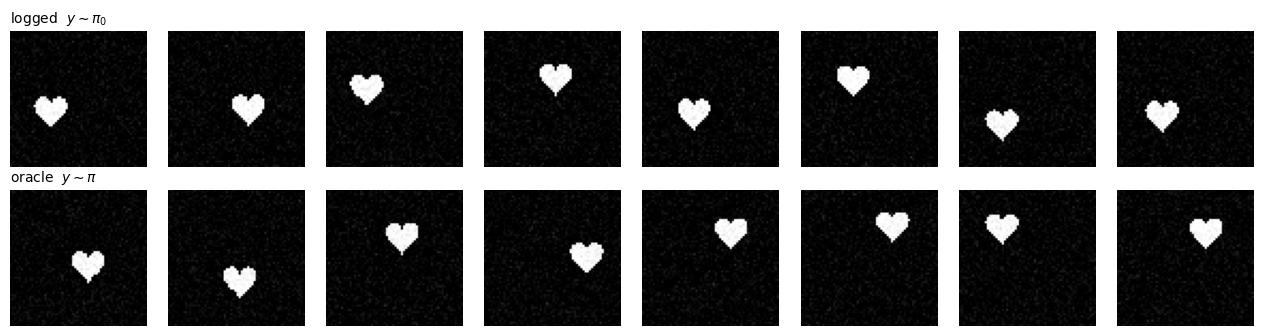

In [2]:
N_OBS = 1000
DSPRITE_NPZ = "../../data/dsprites/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz"
BANK_CACHE = os.path.join(os.path.dirname(DSPRITE_NPZ), "heart_sprite_bank_32x32.npy")

sprite_bank = load_dsprite_bank(DSPRITE_NPZ, cache_path=BANK_CACHE)   # (32, 32, 64, 64)
data = sample_cpme_dsprite_data(sprite_bank, n_samples=N_OBS, sigma_policy=0.5,
                                policy_shift=0.2, pos_gain=3.0, pixel_noise=0.05, seed=1)

oracle_diag = importance_weight_diagnostics(data["importance_weights"].numpy())
print(f"n = {N_OBS}   oracle weights: mean {oracle_diag['mean']:.3f}   "
      f"ESS {oracle_diag['ess']:.0f}   max {oracle_diag['max']:.1f}")

n_show = 8
fig, axes = plt.subplots(2, n_show, figsize=(1.6 * n_show, 3.4))
for j in range(n_show):
    axes[0, j].imshow(data["Y_logged"][j].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    axes[1, j].imshow(data["Y_target"][j].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].set_title(r"logged  $y \sim \pi_0$", loc="left", fontsize=10)
axes[1, 0].set_title(r"oracle  $y \sim \pi$", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 2. Denoising Autoencoder

A symmetric convolutional autoencoder (four stride-2 convolutions to a linear bottleneck
$z \in \mathbb{R}^{32}$, mirrored decoder with a final sigmoid) trained with a
**denoising** objective: reconstruct the clean sprite from a copy corrupted with the same
$0.05$-std pixel noise the DGP adds, so the encoder absorbs the observation noise and the
decoder always renders clean sprites.

Two design decisions. First, the autoencoder is trained on the **full 1024-position sprite
bank**, not the logged sample: it is sampler machinery, not part of the statistical
estimator (the analogue of a pretrained VAE), and the decoder must be able to render
positions that are rare under $\pi_0$ but common under $\pi$. Second, the latent is 32-d
although the sprite manifold is 2-d: reconstruction is perfect from width 8 already, but
the *linear* organisation of the latent — measured by a held-out linear probe
$z \to (\mathrm{pos}_X, \mathrm{pos}_Y)$ — keeps improving with width, and the linear
probe is what predicts feature quality for the kernel.

parameters: 987,873   final training mse 0.00007


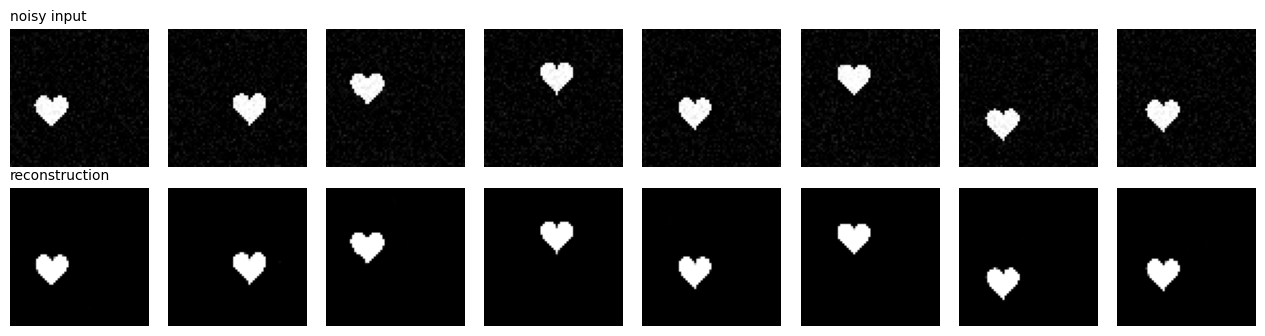

In [3]:
bank_t = torch.as_tensor(sprite_bank, dtype=torch.float32).reshape(1024, 1, 64, 64)
ae, history = train_dsprite_ae(bank_t, latent_dim=32, noise_std=0.05,
                               n_iterations=4000, device=device, verbose=False)
print(f"parameters: {sum(p.numel() for p in ae.parameters()):,}   "
      f"final training mse {history[-1][1]:.5f}")

Y_logged_img = data["Y_logged"].float().reshape(-1, 1, 64, 64).to(device)
Y_target_img = data["Y_target"].float().reshape(-1, 1, 64, 64).to(device)
with torch.no_grad():
    recon_logged = ae(Y_logged_img[:n_show]).cpu()
fig, axes = plt.subplots(2, n_show, figsize=(1.6 * n_show, 3.4))
for j in range(n_show):
    axes[0, j].imshow(Y_logged_img[j, 0].cpu(), cmap="gray", vmin=0, vmax=1)
    axes[1, j].imshow(recon_logged[j, 0], cmap="gray", vmin=0, vmax=1)
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].set_title("noisy input", loc="left", fontsize=10)
axes[1, 0].set_title("reconstruction", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

In [4]:
bank_flat = bank_t.reshape(1024, -1).to(device)
bank_positions = torch.stack(torch.meshgrid(torch.arange(32), torch.arange(32),
                                            indexing="ij"), dim=-1).reshape(1024, 2)

for name, imgs, pos_true in (("logged", Y_logged_img, data["pos_logged"]),
                             ("target", Y_target_img, data["pos_target"])):
    with torch.no_grad():
        recon = torch.cat([ae(imgs[i:i + 256]) for i in range(0, len(imgs), 256)])
    denoise_mse = float(((recon.reshape(len(imgs), -1)
                          - bank_flat[pos_true[:, 0].long() * 32
                                      + pos_true[:, 1].long()]) ** 2).mean())
    snapped = nearest_bank_position(recon.reshape(len(imgs), -1), bank_flat).cpu()
    exact = float((snapped == pos_true.long()).all(dim=1).float().mean())
    print(f"{name:6s}  denoise mse {denoise_mse:.5f} (input noise mse 0.00250)   "
          f"exact position match {exact:.3f}")

Z_bank = encode_in_batches(ae.encode,
                           (bank_t + 0.05 * torch.randn_like(bank_t)).to(device))
probe = position_probe(Z_bank, bank_positions)
print(f"linear probe R^2: posX {probe['posX_r2']:.3f}   posY {probe['posY_r2']:.3f}")

logged  denoise mse 0.00006 (input noise mse 0.00250)   exact position match 1.000
target  denoise mse 0.00007 (input noise mse 0.00250)   exact position match 1.000


linear probe R^2: posX 0.973   posY 0.928


## 3. Cross-Fitted Doubly Robust Weights

All nuisances share one $K = 5$ fold assignment. With $z_i$ the encoded logged outcome and
$\varphi$ the (implicit) outcome feature map:

- **Density ratio.** The logging policy is estimated per fold as a linear-Gaussian
  conditional density $\hat\pi_0^{(-k)}(a \mid x)$ fit on the other folds; the weight
  $\hat w_i = \pi(A_i \mid X_i) / \hat\pi_0^{(-k_i)}(A_i \mid X_i)$ keeps the **known**
  target policy exact in the numerator. Raw ratios — no normalisation or clipping.
- **Conditional mean embedding.** Per fold, a kernel ridge regression on
  $K = K_X \circ K_A$ restricted to the training block, with the ridge $\lambda_k$
  selected on that block. The target-policy embedding $\hat\mu_\pi^{(-k)}(x_i)$ uses a
  Monte Carlo kernel mean over $\tilde a \sim \pi(\cdot \mid x_i)$ draws — an operation on
  the known policy, independent of any oracle sample.
- **One-step correction.** The pseudo-outcome
  $\hat\Gamma_i = \hat\mu_\pi^{(-k_i)}(X_i)
  + \hat w_i\big(\varphi(z_i) - \hat\mu^{(-k_i)}(X_i, A_i)\big)$ averages to
  $\hat\chi_{\mathrm{DR}}(\pi) = \frac1n \sum_i \hat\Gamma_i = \sum_i v_i\,\varphi(z_i)$ —
  still a single weight vector over the encoded outcomes, which is all the sampler sees
  (`cpme_dr_weights_crossfit`).

The kernel lengthscales and the autoencoder are fit once on all data (not cross-fitted);
only the ratio and the conditional mean embedding are. Because the sprite position enters
no coefficient of the estimator, the reweighted position $\sum_i v_i\,\mathrm{pos}_i$ is a
legitimate check against the interventional position mean.

In [5]:
N_FOLDS = 5
fold_ids = make_crossfit_fold_ids(N_OBS, n_folds=N_FOLDS, seed=0)

X_np = data["X"].numpy()
A_np = data["A_logged"].numpy()
log_pi0_hat = crossfit_logging_policy_log_prob(X_np, A_np, fold_ids=fold_ids)
w_hat = importance_weights_from_logging_log_prob(data["target_policy"], X_np, A_np,
                                                 log_pi0_hat)
diag = importance_weight_diagnostics(w_hat, data["importance_weights"].numpy())
print(f"estimated weights: mean {diag['mean']:.3f}   ESS {diag['ess']:.0f}   "
      f"max {diag['max']:.1f}   log-RMSE vs oracle {diag['log_rmse']:.3f}")

Z_log = encode_in_batches(ae.encode, Y_logged_img).cpu()

kernel_x = RBF(use_length_scale_heuristic=True)
kernel_a = RBF(use_length_scale_heuristic=True)
X_t = data["X"].double()
A_t = data["A_logged"].double()
K_x = kernel_x(X_t)
K_a = kernel_a(A_t)
print(f"lengthscales: l_X {float(kernel_x.length_scale):.3f}   "
      f"l_A {float(kernel_a.length_scale):.3f}")

N_RESAMPLE = 8
resample_rng = np.random.default_rng(0)
K_a_target = torch.zeros(N_OBS, N_OBS, dtype=torch.float64)
for _ in range(N_RESAMPLE):
    A_resample = data["target_policy"].sample(X_np, resample_rng)
    K_a_target += kernel_a(A_t, torch.as_tensor(A_resample, dtype=torch.float64))
K_a_target /= N_RESAMPLE

K_pair = K_x * K_a
fold_lambdas = {}
for fold in np.unique(fold_ids):
    train = np.where(fold_ids != fold)[0]
    fold_lambdas[int(fold)], _ = select_regularization(K_pair[train][:, train],
                                                       Z_log[train, 0].double(), seed=0)
print("per-fold lambdas:", fold_lambdas)

w_t = torch.as_tensor(w_hat, dtype=torch.float64)
v_dr = cpme_dr_weights_crossfit(K_x, K_a, K_a_target, w_t, fold_ids, fold_lambdas)
pos_logged = data["pos_logged"].double()
print(f"sum(v) = {float(v_dr.sum()):.3f}   sum|v| = {float(v_dr.abs().sum()):.3f}")
print(f"reweighted position sum(v * pos) = "
      f"({float((v_dr * pos_logged[:, 0]).sum()):.2f}, "
      f"{float((v_dr * pos_logged[:, 1]).sum()):.2f})   "
      f"oracle mean ({float(data['pos_target'][:, 0].mean()):.2f}, "
      f"{float(data['pos_target'][:, 1].mean()):.2f})   "
      f"logged mean ({float(pos_logged[:, 0].mean()):.2f}, "
      f"{float(pos_logged[:, 1].mean()):.2f})")


estimated weights: mean 1.023   ESS 236   max 32.0   log-RMSE vs oracle 0.077


lengthscales: l_X 0.360   l_A 0.667


per-fold lambdas: {0: 0.01, 1: 0.01, 2: 0.01, 3: 0.01, 4: 0.01}
sum(v) = 1.005   sum|v| = 1.754
reweighted position sum(v * pos) = (18.69, 18.69)   oracle mean (17.95, 18.95)   logged mean (12.40, 12.55)


## 4. Kernel Herding from the DR Embedding

The candidate set is the encoded logged outcomes, so every selection is a real observed
sprite image. The kernel is the Riesz (energy) kernel used by the flow notebook, evaluated
in the same standardised latent, and the target is the same $\hat\chi_{\mathrm{DR}}(\pi)$.

Herding selects with replacement, so the number of distinct selections and the largest
multiplicity are reported: they say whether the result is a sample spread over the candidate
set or a quantisation concentrated on a few points.

In [6]:
M_SAMPLES = N_OBS

latent_mean = Z_log.mean(dim=0, keepdim=True)
latent_std = Z_log.std(dim=0, keepdim=True).clamp_min(1e-3)
to_flow = lambda z: ((z - latent_mean) / latent_std).float()
Z_std = to_flow(Z_log).to(device)

herd_kernel = RieszKernel()
v_herd = v_dr.float().to(device)
herded_latents, herded_idx = kernel_herding(v_herd, herd_kernel, Z_std, Z_std,
                                            M_SAMPLES, return_indices=True)
herded_images = data["Y_logged"].float()[herded_idx.cpu()]
herded_pos = data["pos_logged"].float()[herded_idx.cpu()]

diagnostics = herding_diagnostics(herded_idx.cpu(), n_candidates=N_OBS)
print(f"herding: {diagnostics['n_selected']} selections   "
      f"{diagnostics['n_unique']} distinct ({diagnostics['unique_fraction']:.1%})   "
      f"max multiplicity {diagnostics['max_multiplicity']}   "
      f"candidate coverage {diagnostics['candidate_coverage']:.1%}")
print(f"reweighted position sum(v * pos) = "
      f"({float((v_dr * pos_logged[:, 0]).sum()):.2f}, "
      f"{float((v_dr * pos_logged[:, 1]).sum()):.2f})   "
      f"herded mean ({float(herded_pos[:, 0].mean()):.2f}, "
      f"{float(herded_pos[:, 1].mean()):.2f})   "
      f"oracle mean ({float(data['pos_target'][:, 0].mean()):.2f}, "
      f"{float(data['pos_target'][:, 1].mean()):.2f})")

herding: 1000 selections   372 distinct (37.2%)   max multiplicity 35   candidate coverage 37.2%
reweighted position sum(v * pos) = (18.69, 18.69)   herded mean (18.76, 18.63)   oracle mean (17.95, 18.95)


## 5. Selected Sprites

Herding returns logged images unchanged, so no decoding step is involved and there is
nothing to snap: the selections *are* observed sprites. The rows below are the observed
sample, the herded selection, and an oracle draw.

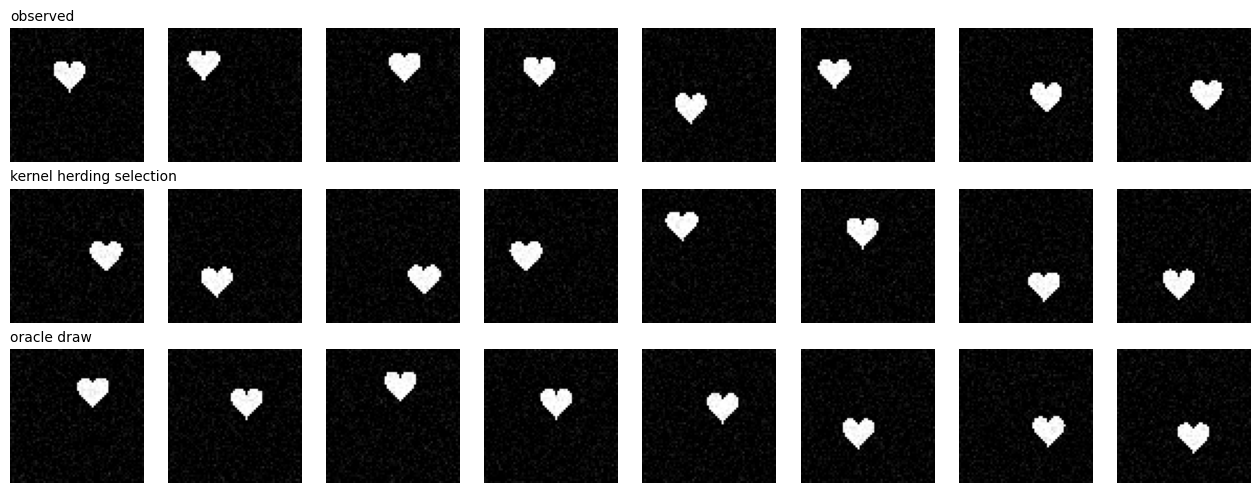

In [7]:
oracle_images = data["Y_target"].float()
idx = 87
fig, axes = plt.subplots(3, n_show, figsize=(1.6 * n_show, 5.0))
for j in range(n_show):
    axes[0, j].imshow(data["Y_logged"][idx + j].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    axes[1, j].imshow(herded_images[idx + j].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    axes[2, j].imshow(oracle_images[idx + j].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
for ax in axes.ravel():
    ax.axis("off")
for row, label in enumerate(("observed", "kernel herding selection", "oracle draw")):
    axes[row, 0].set_title(label, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 6. Metric Evaluation (Images, No Snapping)

Scored exactly as in the flow notebook: against oracle images from 10 fresh draws of the
interventional law, reporting the mean $\pm$ std of the energy distance (squared MMD with
the Riesz kernel) and sliced Wasserstein distances of both orders.

The MMD flow is run here as well, from the same latents, target and seed, so the two
samplers can be compared within a single run rather than across notebooks.

In [8]:
energy_kernel = RieszKernel()
fresh = [sample_cpme_dsprite_data(sprite_bank, n_samples=N_OBS, sigma_policy=0.5,
                                  policy_shift=0.2, pos_gain=3.0, pixel_noise=0.05, seed=s)
         for s in range(70, 80)]
fresh_pos = [d["pos_target"].double() for d in fresh]
fresh_img = [d["Y_target"].float() for d in fresh]


def score(sample, references):
    sample = sample.double()
    stats = []
    for metric in (lambda a, b: float(squared_mmd(energy_kernel, a, b)),
                   lambda a, b: float(sliced_wasserstein(a, b, p=1, seed=0)),
                   lambda a, b: float(sliced_wasserstein(a, b, p=2, seed=0))):
        stats.append((np.mean([metric(sample, r.double()) for r in references]),
                      np.std([metric(sample, r.double()) for r in references])))
    return stats


initial_particles = Z_std.clone()
flow_particles, flow_info = adamw_riesz_flow(
    initial_particles, Z_std, target_weights=v_herd, sliced=False, n_iterations=2000,
    learning_rate=0.01, warmup_steps=100, verbose=False)
from_flow = lambda z: z.cpu().float() * latent_std + latent_mean
with torch.no_grad():
    flow_images = torch.cat([ae.decode(from_flow(flow_particles[i:i + 256]).to(device))
                             for i in range(0, N_OBS, 256)]).reshape(N_OBS, -1).cpu()

clean_oracle = bank_flat.cpu()[(data["pos_target"].long()[:, 0] * 32
                               + data["pos_target"].long()[:, 1])].float()
rows = {"logged (base)": data["Y_logged"].float(),
        "kernel herding": herded_images,
        "DR Riesz MMD flow": flow_images,
        "oracle draw, noisy (floor)": oracle_images,
        "oracle positions, clean (floor for a clean-output sampler)": clean_oracle}
print(f"{'sample':24s} {'energy dist':>16s} {'SW1':>16s} {'SW2':>16s}")
for name, images in rows.items():
    print(f"{name:24s} " + " ".join(f"{m:8.4f} +/- {s:.3f}"
                                    for m, s in score(images, fresh_img)))

# Herding returns RAW logged images, which carry the DGP's pixel noise: their
# distance to the nearest CLEAN bank sprite is the noise norm 0.05*sqrt(4096) = 3.20
# by construction, not a defect. To compare like with like, both samplers are also
# measured after an autoencoder round trip, which is what the flow's decoder emits.
with torch.no_grad():
    herd_denoised = torch.cat(
        [ae(herded_images[i:i + 256].reshape(-1, 1, 64, 64).to(device))
         for i in range(0, N_OBS, 256)]).reshape(N_OBS, -1)
_, herd_raw_off = snap_to_bank(herded_images.to(device), bank_flat)
_, herd_off = snap_to_bank(herd_denoised, bank_flat)
_, flow_off = snap_to_bank(flow_images.to(device), bank_flat)
print(f"\noff-manifold distance to the nearest clean sprite")
print(f"  herding, raw selections   median {float(herd_raw_off.median()):5.2f}   "
      f"(= the DGP pixel-noise norm 3.20, by construction)")
print(f"  herding, after AE         median {float(herd_off.median()):5.2f}   "
      f"frac>3 {float((herd_off > 3).float().mean()):.3f}")
print(f"  DR Riesz flow (decoded)   median {float(flow_off.median()):5.2f}   "
      f"frac>3 {float((flow_off > 3).float().mean()):.3f}")

sample                        energy dist              SW1              SW2


logged (base)              0.6240 +/- 0.031   0.0404 +/- 0.001   0.0523 +/- 0.001


kernel herding             0.1068 +/- 0.006   0.0181 +/- 0.001   0.0241 +/- 0.001


DR Riesz MMD flow          0.1143 +/- 0.007   0.0188 +/- 0.001   0.0252 +/- 0.001


oracle draw, noisy (floor)   0.0352 +/- 0.006   0.0103 +/- 0.001   0.0138 +/- 0.001


oracle positions, clean (floor for a clean-output sampler)   0.0447 +/- 0.007   0.0120 +/- 0.001   0.0160 +/- 0.001

off-manifold distance to the nearest clean sprite
  herding, raw selections   median  3.20   (= the DGP pixel-noise norm 3.20, by construction)
  herding, after AE         median  0.41   frac>3 0.000
  DR Riesz flow (decoded)   median  0.48   frac>3 0.039


## 7. Sample or Quantisation?

Herding cannot leave the manifold, but it can collapse onto a few candidates. Two
diagnostics separate a spread-out sample from a quantisation: the multiplicity profile of
the selections, and the coefficient of variation of nearest-neighbour spacings in position
space. An i.i.d. sample has a characteristic spacing spread; a quantisation with repeated
points has near-zero spacings and a much larger coefficient of variation.

sample                     unique  max mult  spacing CV
kernel herding                372        35        2.71
DR Riesz MMD flow               -         -        2.83
oracle draw                     -         -        1.42


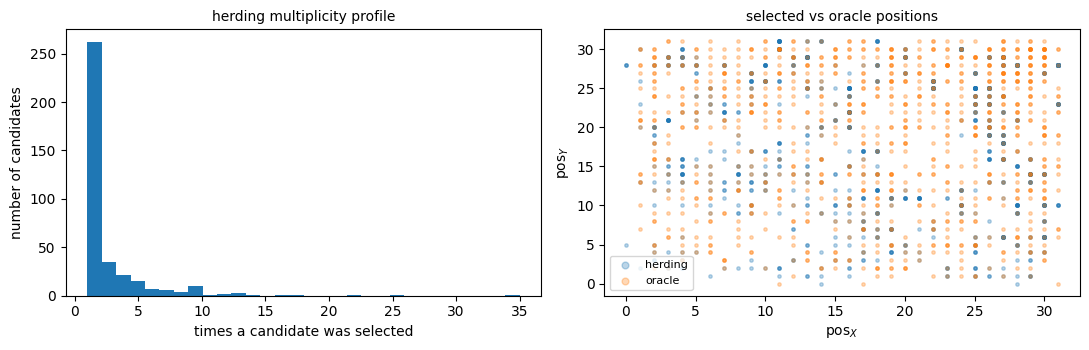

In [9]:
def spacing_cv(positions):
    positions = positions.double()
    distances = torch.cdist(positions, positions)
    distances.fill_diagonal_(float("inf"))
    nearest = distances.min(dim=1).values
    return float(nearest.std() / nearest.mean().clamp_min(1e-12))


flow_pos = snap_to_bank(flow_images.to(device), bank_flat)[0].cpu().float()
print(f"{'sample':24s} {'unique':>8s} {'max mult':>9s} {'spacing CV':>11s}")
for name, positions, idxs in (("kernel herding", herded_pos, herded_idx.cpu()),
                              ("DR Riesz MMD flow", flow_pos, None),
                              ("oracle draw", data["pos_target"].float(), None)):
    if idxs is not None:
        d = herding_diagnostics(idxs, n_candidates=N_OBS)
        unique, mult = f"{d['n_unique']}", f"{d['max_multiplicity']}"
    else:
        unique, mult = "-", "-"
    print(f"{name:24s} {unique:>8s} {mult:>9s} {spacing_cv(positions):11.2f}")

counts = torch.bincount(herded_idx.cpu(), minlength=N_OBS)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(counts[counts > 0].numpy(), bins=30, color="tab:blue")
axes[0].set_xlabel("times a candidate was selected")
axes[0].set_ylabel("number of candidates")
axes[0].set_title("herding multiplicity profile", fontsize=10)
axes[1].scatter(herded_pos[:, 0], herded_pos[:, 1], s=6, alpha=0.3, label="herding")
axes[1].scatter(data["pos_target"][:, 0], data["pos_target"][:, 1], s=6, alpha=0.3,
                label="oracle")
axes[1].set_xlabel(r"$\mathrm{pos}_X$")
axes[1].set_ylabel(r"$\mathrm{pos}_Y$")
axes[1].legend(fontsize=8, markerscale=2)
axes[1].set_title("selected vs oracle positions", fontsize=10)
plt.tight_layout()
plt.show()

## 8. The Snapped View

For completeness, the position law that the flow notebook reports in its Section 8. For
herding this view is exact rather than approximate: the selections are logged images, so
snapping recovers the position they were rendered at and discards nothing.

In [10]:
print("position law")
print(f"{'sample':24s} {'energy dist':>16s} {'SW1':>16s} {'SW2':>16s}")
for name, positions in {"logged (base)": pos_logged,
                        "kernel herding": herded_pos,
                        "DR Riesz MMD flow": flow_pos,
                        "oracle draw (floor)": data["pos_target"].double()}.items():
    print(f"{name:24s} " + " ".join(f"{m:8.4f} +/- {s:.3f}"
                                    for m, s in score(positions, fresh_pos)))

position law
sample                        energy dist              SW1              SW2


logged (base)              3.9893 +/- 0.190   5.4892 +/- 0.135   6.3213 +/- 0.164


kernel herding             0.0454 +/- 0.011   0.5491 +/- 0.068   0.6898 +/- 0.079


DR Riesz MMD flow          0.0472 +/- 0.012   0.5610 +/- 0.068   0.7032 +/- 0.079


oracle draw (floor)        0.0489 +/- 0.025   0.5644 +/- 0.154   0.6811 +/- 0.168


## Summary

- **Same estimation, different sampler.** The data, autoencoder and cross-fitted DR weights
  are copied cell for cell from the flow notebook, so the comparison below isolates the
  sampler. Herding hits the estimated target: the selected mean position $(18.76, 18.63)$
  matches the reweighted target $\sum_i v_i\,\mathrm{pos}_i = (18.69, 18.69)$, against a
  logged mean of $(12.40, 12.55)$.
- **The two samplers are near-equivalent on distributional accuracy**, with herding
  marginally ahead: pixel energy distance $0.107$ (herding) vs $0.115$ (flow), from a logged
  base of $0.624$; SW2 $0.0241$ vs $0.0252$. In the position law, $0.045$ vs $0.047$ against
  a floor of $0.049$. Neither difference is large relative to the spread over oracle draws.
- **Read each against its own floor.** Herding returns real logged outcomes, so its
  reference is the noisy oracle draw ($0.035$). The flow decodes through a *denoising*
  autoencoder and emits clean sprites, so it cannot reproduce observation noise and its
  reference is clean sprites at the oracle's own positions ($0.045$). On that basis herding
  is $3.0\times$ its floor and the flow $2.6\times$ — closer than the raw numbers suggest.
- **Manifold validity: herding cannot fail, and does not.** Its selections are observations,
  so their distance to the nearest clean sprite is exactly the DGP's pixel-noise norm
  $0.05\sqrt{4096} = 3.20$ by construction; passed through the autoencoder for a like-for-like
  comparison they sit at $0.41$, with nothing beyond the threshold. The flow reaches $0.48$
  with $3.9\%$ beyond it. That residual tail is the price of synthesis.
- **The price of selection is repetition.** Herding draws $1000$ samples from $1000$
  candidates but uses only $372$ of them, with one candidate chosen $35$ times. Its
  nearest-neighbour spacing coefficient of variation is $2.71$ against $1.42$ for an i.i.d.
  oracle draw — the signature of a quantisation rather than a sample. The flow, at $2.83$,
  is no better on this axis here, though for a different reason: it moves particles into the
  gaps between grid points rather than stacking them on a few.
- **The trade-off, concretely.** Herding is safe and cheap and cannot leave the data, but it
  can only return outcomes already observed and it concentrates. The flow can synthesise
  outcomes not present in the sample, at the cost of a small off-manifold tail. On this
  design, where every valid outcome is one of 1024 observed grid points, selection is
  sufficient; the flow's advantage would show on designs where the target places mass where
  no observation lies.